# 03: Why the transfer works or fails (Test 6)

The classifier never sees waveforms, only the 11 RF-v2 feature values. So the question
for every feature is: do DAS events land in the range the model saw on seismometers?

- Inside the seismometer range: the model has seen values like this before.
- Outside it: the model is guessing, and that feature is the first suspect when a DAS
  event gets the wrong label.

**Pass criterion (Test 6):** every gap between seismometer and DAS feature values is
either explained or listed as a limitation. Check date: Nov 25.

**Inputs** (feature CSVs, one row per window, one column per feature, plus `label`):

| What | Who | Where this notebook looks |
|---|---|---|
| Seismometer features, GTUNE (UNE) + earthquakes (EQ), with `dist_deg` and `snr_pass` | Sammy (`scripts/build_features.py`) | `data/features/gtune_une.csv`, `data/features/eq.csv` |
| Stacked Ridgecrest DAS blocks with a detected arrival | Sammy (`scripts/predict_das.py`) | `data/features/ridgecrest_blocks.csv` |
| Single DAS channels (notebook 02, section 9) | Sammy | `data/features/*_features.csv` |
| Synthetic DAS explosions from GTUNE | Himi | `data/features/synthetic_une/*.csv` |
| Real DAS blasts (DAG-2, Viens et al. 2025) | Sofian + Mahmoud | `data/features/blasts/*.csv` |

Seismometer rows are kept only where `snr_pass` is true, the same rule `train_rf.py` uses, so the comparison
uses exactly the traces the model was trained on. All Ridgecrest events are under 5°, so DAS is compared with
the **under-5° seismometer earthquakes** (handout table, Nov 17 plan).

Any input that is missing is skipped, so this runs at every stage. Rerun it once each file lands.

In [1]:
import sys
sys.path.append("..")  # so 'src' imports work from inside notebooks/

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from src.compare import (FEATURES_11, HANDOUT_MEDIANS, load_features, handout_errors,
                         bin_medians, range_table, plot_overlays)

FEAT = Path("../data/features")
ASSETS = Path("../assets")

# Seismometer features from scripts/build_features.py (one file per class)
seis = pd.concat([load_features(str(FEAT / "gtune_une.csv"), label="UNE", source="seismometer"),
                  load_features(str(FEAT / "eq.csv"), label="EQ", source="seismometer")],
                 ignore_index=True)
if "snr_pass" in seis:                      # same traces train_rf.py trains on
    print(f"seismometer: keeping {int(seis['snr_pass'].sum())} of {len(seis)} rows that pass the SNR rule")
    seis = seis[seis["snr_pass"].astype(bool)].reset_index(drop=True)

# Stacked Ridgecrest DAS blocks from scripts/predict_das.py
das_stack = load_features(str(FEAT / "ridgecrest_blocks.csv"), label="EQ", source="DAS stacked")
das_chan  = load_features(str(FEAT / "*_features.csv"), label="EQ", source="DAS single channel")
synth     = load_features(str(FEAT / "synthetic_une" / "*.csv"), label="UNE", source="synthetic DAS")
blasts    = load_features(str(FEAT / "blasts" / "*.csv"), label="UNE", source="real DAS blasts")

inputs = {"seismometer": seis, "DAS stacked": das_stack, "DAS single channel": das_chan,
          "synthetic DAS UNE": synth, "real DAS blasts": blasts}
for name, df in inputs.items():
    print(f"{name:20s} {'MISSING' if df.empty else f'{len(df):6d} rows'}")

seis_eq = seis[seis["label"] == "EQ"] if not seis.empty else seis
seis_une = seis[seis["label"] == "UNE"] if not seis.empty else seis
# every Ridgecrest event is under 5 deg, so that is the fair earthquake reference
seis_eq_lt5 = seis_eq[seis_eq["dist_deg"] < 5] if "dist_deg" in seis_eq else seis_eq
print(f"seismometer EQ under 5 deg: {len(seis_eq_lt5)} rows")
das = das_stack if not das_stack.empty else das_chan   # stacked events are the real test unit
print(f"\nDAS rows used below: {das['source'].iloc[0] if not das.empty else 'none'}")

seismometer: keeping 388 of 977 rows that pass the SNR rule
seismometer             388 rows
DAS stacked             776 rows
DAS single channel   MISSING
synthetic DAS UNE    MISSING
real DAS blasts      MISSING
seismometer EQ under 5 deg: 94 rows

DAS rows used below: DAS stacked


## 1. The two handout errors

Checked on our own feature rows, not just on paper:

- `peak` is the largest absolute sample. After peak normalisation it is 1.0 on every window, so it carries no information.
- `crest_factor` (Appendix B) is Peak / RMS, the same formula as `peak_rms_ratio` (Appendix A).

That is why we train on 11 features, not 13.

In [2]:
for name, df in inputs.items():
    if not df.empty and "peak" in df:
        print(name, handout_errors(df))

seismometer {'peak_values': [1.0], 'peak_is_constant': True, 'crest_minus_ratio': 0.0, 'crest_is_duplicate': True}
DAS stacked {'peak_values': [1.0], 'peak_is_constant': True, 'crest_minus_ratio': 0.0, 'crest_is_duplicate': True}


## 2. Our seismometer features vs the handout

The handout lists seismometer feature medians per distance bin. If our GTUNE + CREW features are built the
same way, our medians should land close to his. A big mismatch means our preprocessing differs from his, and
that has to be fixed before any DAS comparison means anything.

In [3]:
if seis.empty or "dist_deg" not in seis:
    print("Waiting on data/features/eq.csv and gtune_une.csv (run scripts/build_features.py).")
else:
    display(bin_medians(seis).round(2))

,ours <5,handout <5,ours 5-10,handout 5-10,ours 10-20,handout 10-20
feature,,,,,,
dominant_frequency,1.03,1.68,0.92,0.92,0.75,0.78
spectral_centroid,2.36,3.39,2.56,2.65,2.29,2.34
bandwidth,1.72,2.10,1.66,1.91,1.85,1.75
peak_rms_ratio,4.76,5.10,4.77,4.03,3.92,3.90
duration_20,312.00,13.95,323.50,22.10,481.00,23.15
duration_10,567.50,28.10,600.50,36.10,777.50,36.95


## 3. Where the DAS earthquakes sit

DAS events are earthquakes, so they are compared with the seismometer **earthquakes under 5°**,
because every Ridgecrest event is under 5° and distance changes the features (section 2).
`DAS pct` is the percentile of the DAS median within the seismometer values (50 = right in the middle);
`DAS inside` is the share of DAS rows inside the middle 90% of seismometer values.

Until the seismometer features exist, the fallback below compares the DAS median with the handout's
under-5° median (the Ridgecrest events are local).

In [4]:
if das.empty:
    print("No DAS features yet.")
elif seis_eq_lt5.empty:
    rows = [{"feature": f, "DAS median": das[f].median(), "handout <5 median": m["<5"]}
            for f, m in HANDOUT_MEDIANS.items()]
    display(pd.DataFrame(rows).set_index("feature").round(2))
else:
    eq_table = range_table(seis_eq_lt5, das)
    display(eq_table.round(2))
    print("Features to explain:", list(eq_table.index[eq_table["verdict"] != "inside"]))

,seis p5,seis p95,DAS median,DAS pct,DAS inside,verdict
feature,,,,,,
rms,0.12,0.29,0.13,9.57,0.55,inside
peak_rms_ratio,3.46,8.26,7.48,90.43,0.55,inside
early_e,0.00,0.08,0.03,76.60,0.92,inside
middle_e,0.00,0.11,0.03,48.94,0.92,inside
late_e,0.01,0.11,0.01,4.26,0.36,edge
dominant_frequency,0.57,3.27,2.17,85.11,0.68,inside
spectral_centroid,1.81,4.11,4.58,97.87,0.24,OUTSIDE
bandwidth,1.40,2.62,2.48,88.30,0.92,inside
duration_20,96.90,523.35,117.00,9.57,0.53,inside


Features to explain: ['late_e', 'spectral_centroid', 'energy_centroid_time']


## 4. Figure for the slides and the report

One panel per feature. Dashed lines are the handout's per-bin seismometer medians.

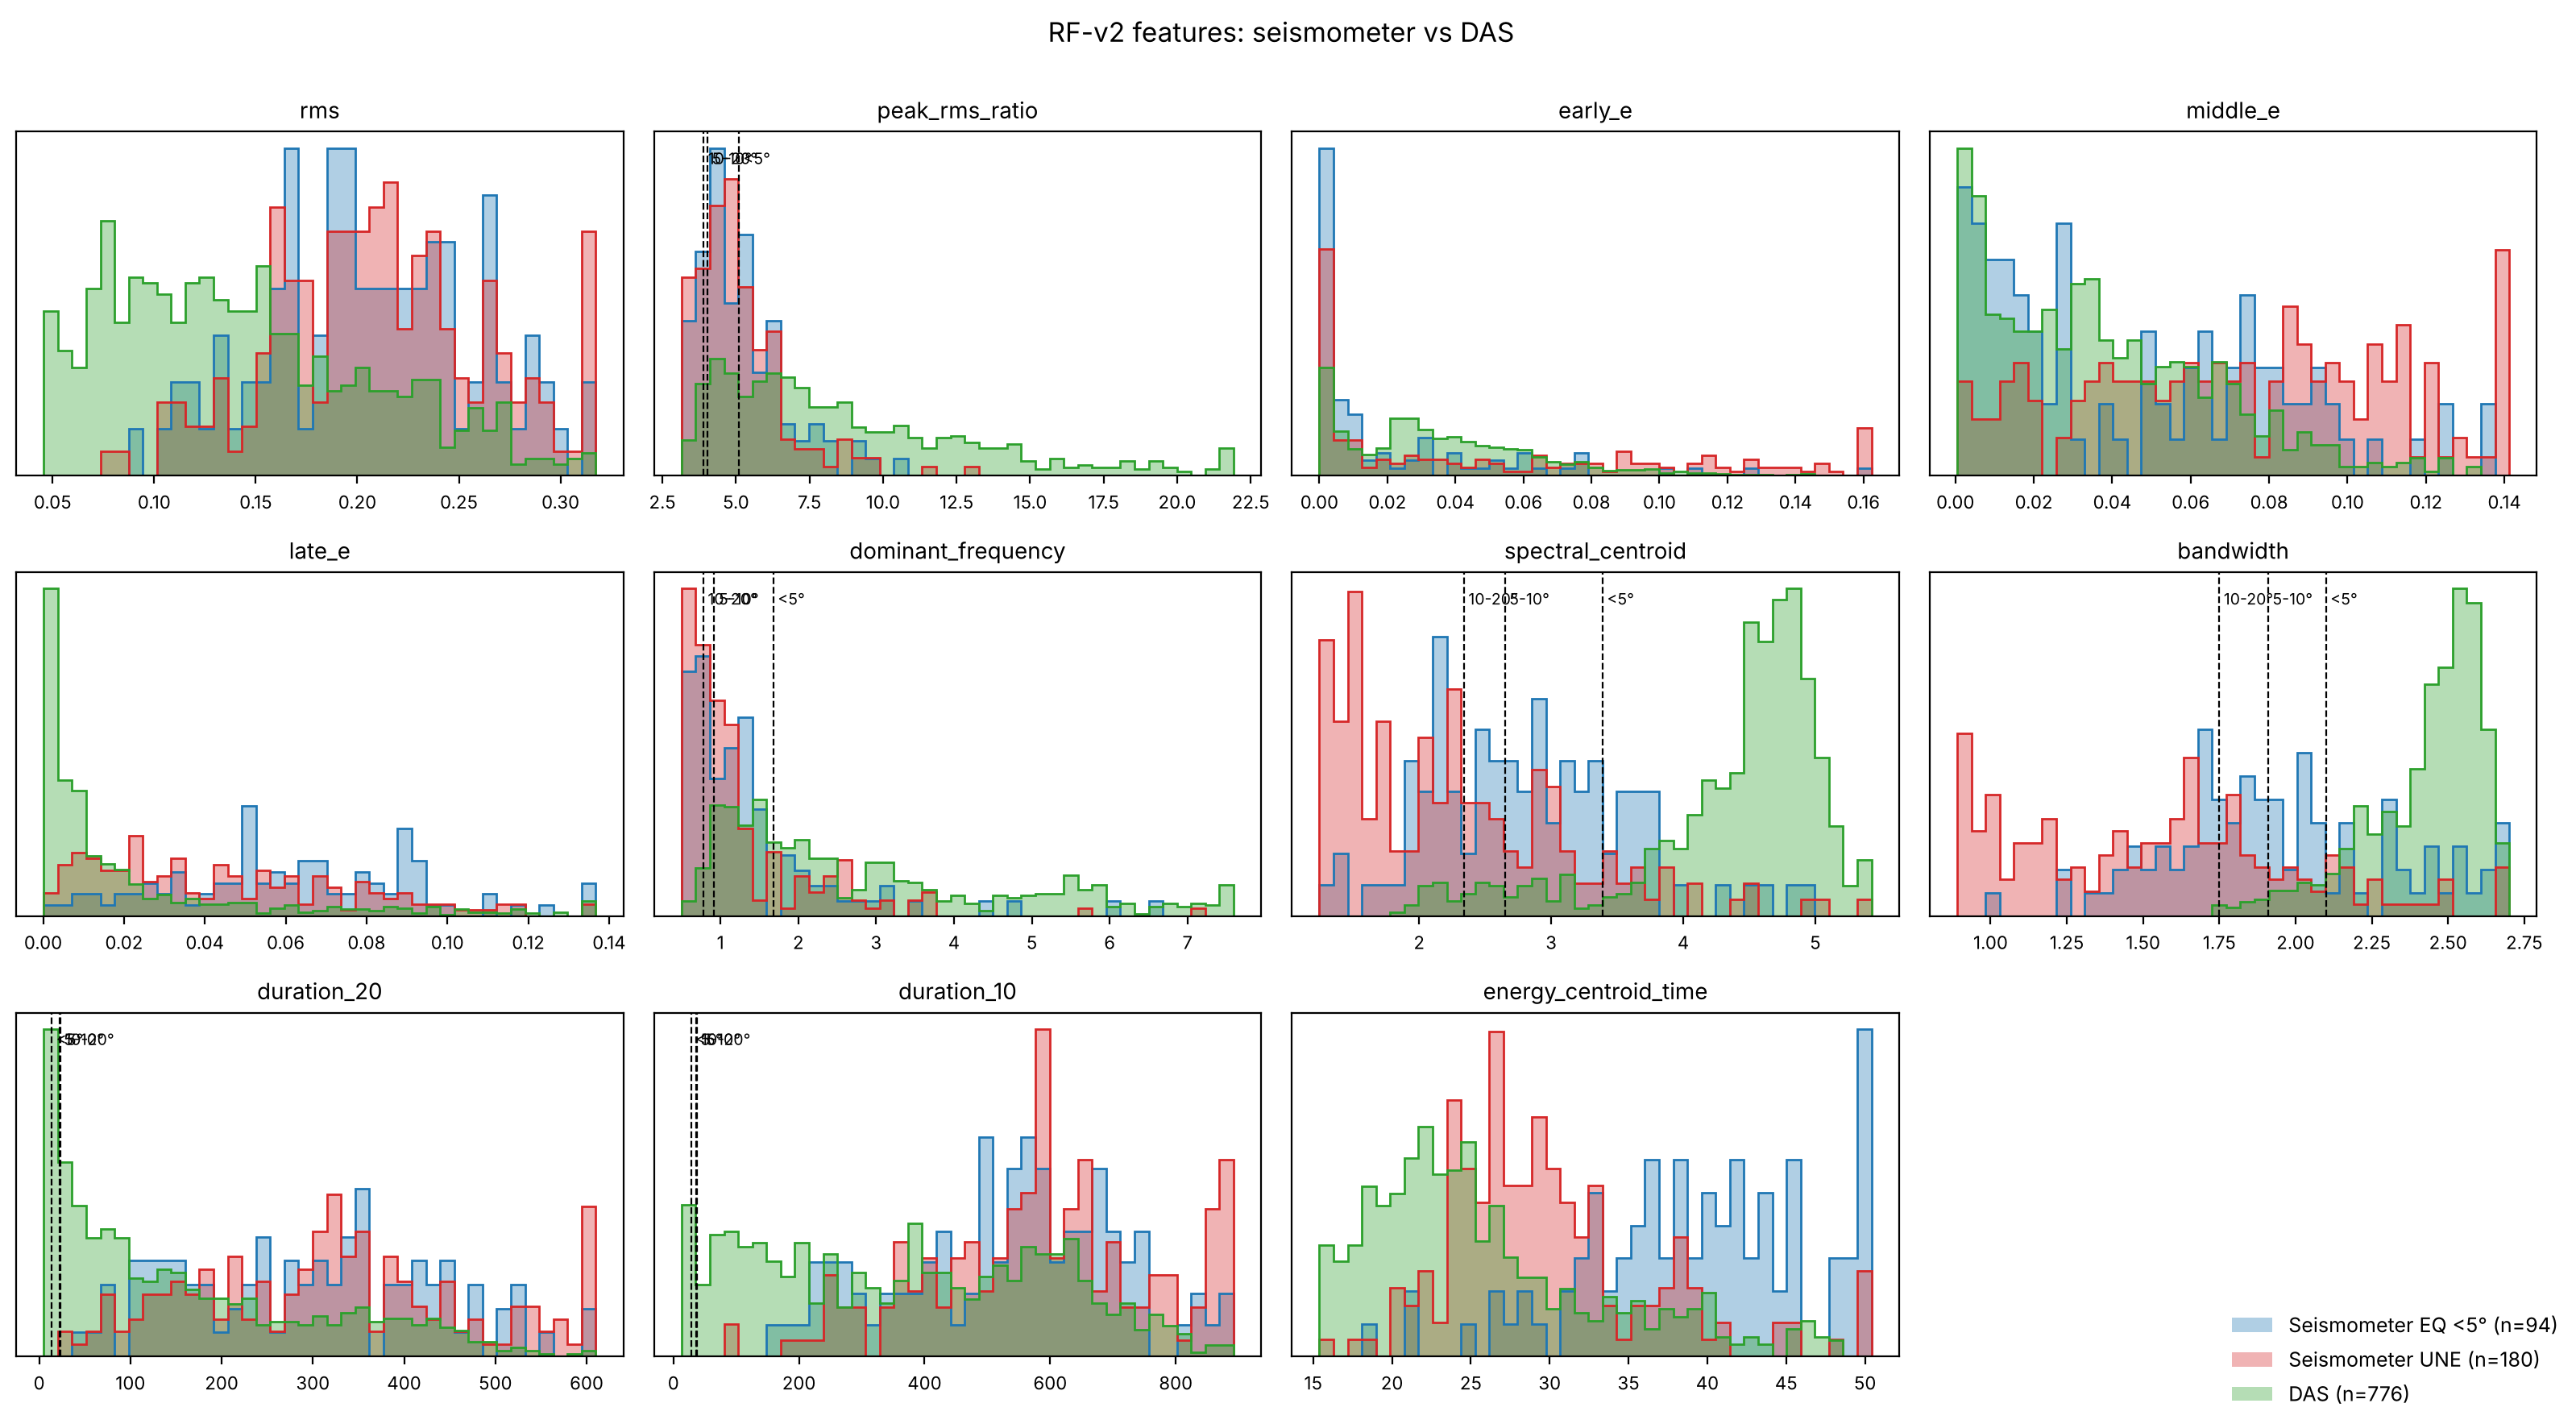

In [5]:
groups = {"Seismometer EQ <5°": seis_eq_lt5, "Seismometer UNE": seis_une, "DAS": das}
if any(not g.empty for g in groups.values()):
    fig = plot_overlays(groups, title="RF-v2 features: seismometer vs DAS",
                        path=str(ASSETS / "fig_feature_compare.png"))
    plt.show()

## 5. The explosion side

Synthetic DAS explosions and the real DAS blasts are compared with the seismometer **explosions** (GTUNE).
If the synthetic and real DAS explosions land in different places, the GTUNE-to-DAS conversion is the suspect.

In [6]:
for name, df in {"synthetic DAS UNE": synth, "real DAS blasts": blasts}.items():
    if df.empty or seis_une.empty:
        print(f"{name}: waiting on {'this file' if df.empty else 'GTUNE features'}")
    else:
        print(name); display(range_table(seis_une, df, ref_label="UNE").round(2))

synthetic DAS UNE: waiting on this file
real DAS blasts: waiting on this file


## Reading the results

- **inside**: DAS looks like seismometer data for this feature. No explanation needed.
- **edge**: DAS overlaps but is shifted. Say which way and why (e.g. DAS measures strain rate, which weights high frequencies more than velocity).
- **OUTSIDE**: the model has never seen values like this. Explain it, or list it as a limitation.

On single channels we already expect `duration_10`, `duration_20` and `energy_centroid_time` to come out
OUTSIDE, because a single channel is mostly noise (see `fig_features_three.png`). The stacked events are
the real test.